In [1]:
print("=" * 80)
print("Notebook 04 - Baseline Machine Learning Models")
print("=" * 80)
print("Starting baseline model pipeline...")

Notebook 04 - Baseline Machine Learning Models
Starting baseline model pipeline...


In [2]:
import os
from pathlib import Path

# Safe dynamic path resolution
try:
    from google.colab import drive
    if Path('/content').exists():
        drive.mount('/content/drive')
        PROJECT_DIR = Path('/content/drive/MyDrive/AI-Cybersecurity-Assistant')
    else:
        PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
except Exception:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

SPLIT_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "processed",
    "CIC-IDS2017_splits"
)

TRAIN_FILE = os.path.join(SPLIT_DIR, "train.csv")
TEST_FILE = os.path.join(SPLIT_DIR, "test.csv")

NEW_RESULTS_DIR = PROJECT_DIR / "new notebook results"
TABLES_DIR = NEW_RESULTS_DIR / "tables"
PICTURES_DIR = NEW_RESULTS_DIR / "pictures"
MODELS_DIR = NEW_RESULTS_DIR / "models"

for d in [TABLES_DIR, PICTURES_DIR, MODELS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT ROOT DIRECTORY:", PROJECT_DIR)
print("TRAIN FILE:", TRAIN_FILE)
print("TEST FILE:", TEST_FILE)


BASELINE MODEL DATA PATHS
Training file:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/data/processed/CIC-IDS2017_splits/train.csv

Testing file:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/data/processed/CIC-IDS2017_splits/test.csv

Training file exists: True
Testing file exists: True


In [3]:
RANDOM_STATE = 42
TARGET_COLUMN = "Label_ID"

print("BASELINE MODEL CONFIGURATION")
print("=" * 80)

print("Target column:", TARGET_COLUMN)
print("Random state:", RANDOM_STATE)

print("\nEvaluation strategy:")
print("- Fixed training set")
print("- Fixed testing set")
print("- Same test set for all baseline models")
print("- Multiclass classification")

BASELINE MODEL CONFIGURATION
Target column: Label_ID
Random state: 42

Evaluation strategy:
- Fixed training set
- Fixed testing set
- Same test set for all baseline models
- Multiclass classification


In [4]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("BASELINE MACHINE-LEARNING LIBRARIES")
print("=" * 80)

print("NumPy: imported")
print("Pandas: imported")
print("Scikit-learn metrics: imported")

print("\n✅ Required baseline libraries loaded successfully.")

BASELINE MACHINE-LEARNING LIBRARIES
NumPy: imported
Pandas: imported
Scikit-learn metrics: imported

✅ Required baseline libraries loaded successfully.


In [5]:
SAMPLE_ROWS = 10_000

print("LOADING BASELINE MODEL SAMPLE")
print("=" * 80)

train_sample = pd.read_csv(
    TRAIN_FILE,
    nrows=SAMPLE_ROWS,
    low_memory=False
)

test_sample = pd.read_csv(
    TEST_FILE,
    nrows=SAMPLE_ROWS,
    low_memory=False
)

print("Training sample shape:", train_sample.shape)
print("Testing sample shape :", test_sample.shape)

print("\nTraining sample columns:", len(train_sample.columns))
print("Testing sample columns :", len(test_sample.columns))

print("\nTarget column present in training:",
      TARGET_COLUMN in train_sample.columns)

print("Target column present in testing :",
      TARGET_COLUMN in test_sample.columns)

print("\nTraining sample class count:")
print(train_sample[TARGET_COLUMN].nunique())

print("\nTesting sample class count:")
print(test_sample[TARGET_COLUMN].nunique())

print("\n✅ Baseline dataset samples loaded successfully.")

LOADING BASELINE MODEL SAMPLE
Training sample shape: (10000, 79)
Testing sample shape : (10000, 79)

Training sample columns: 79
Testing sample columns : 79

Target column present in training: True
Target column present in testing : True

Training sample class count:
13

Testing sample class count:
12

✅ Baseline dataset samples loaded successfully.


In [6]:
FEATURE_COLUMNS = [
    column
    for column in train_sample.columns
    if column != TARGET_COLUMN
]

print("BASELINE FEATURE CONFIGURATION")
print("=" * 80)

print("Number of features:", len(FEATURE_COLUMNS))
print("Target column:", TARGET_COLUMN)

print("\nFirst 15 features:")
for i, feature in enumerate(
    FEATURE_COLUMNS[:15],
    start=1
):
    print(f"{i}. {feature}")

print("\nTarget included in features:",
      TARGET_COLUMN in FEATURE_COLUMNS)

if len(FEATURE_COLUMNS) == 78:
    print("\n✅ Exactly 78 features identified.")
else:
    print("\n⚠️ Unexpected number of features.")

BASELINE FEATURE CONFIGURATION
Number of features: 78
Target column: Label_ID

First 15 features:
1. Destination Port
2. Flow Duration
3. Total Fwd Packets
4. Total Backward Packets
5. Total Length of Fwd Packets
6. Total Length of Bwd Packets
7. Fwd Packet Length Max
8. Fwd Packet Length Min
9. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s

Target included in features: False

✅ Exactly 78 features identified.


In [7]:
print("BASELINE SAMPLE DATA QUALITY CHECK")
print("=" * 80)

train_missing = int(
    train_sample[FEATURE_COLUMNS]
    .isna()
    .sum()
    .sum()
)

test_missing = int(
    test_sample[FEATURE_COLUMNS]
    .isna()
    .sum()
    .sum()
)

train_infinite = int(
    np.isinf(
        train_sample[FEATURE_COLUMNS]
    ).sum()
    .sum()
)

test_infinite = int(
    np.isinf(
        test_sample[FEATURE_COLUMNS]
    ).sum()
    .sum()
)

train_non_numeric = train_sample[
    FEATURE_COLUMNS
].select_dtypes(
    exclude="number"
).columns.tolist()

test_non_numeric = test_sample[
    FEATURE_COLUMNS
].select_dtypes(
    exclude="number"
).columns.tolist()

print("Training sample missing values:", train_missing)
print("Testing sample missing values :", test_missing)

print("\nTraining sample infinite values:", train_infinite)
print("Testing sample infinite values :", test_infinite)

print("\nTraining non-numeric features:",
      len(train_non_numeric))

print("Testing non-numeric features:",
      len(test_non_numeric))

if (
    train_missing == 0
    and test_missing == 0
    and train_infinite == 0
    and test_infinite == 0
    and len(train_non_numeric) == 0
    and len(test_non_numeric) == 0
):
    print("\n✅ Baseline samples passed data-quality validation.")
else:
    print("\n⚠️ Baseline samples require investigation.")

BASELINE SAMPLE DATA QUALITY CHECK
Training sample missing values: 0
Testing sample missing values : 0

Training sample infinite values: 0
Testing sample infinite values : 0

Training non-numeric features: 0
Testing non-numeric features: 0

✅ Baseline samples passed data-quality validation.


In [8]:
BASELINE_METRICS = [
    "Accuracy",
    "Precision (Weighted)",
    "Recall (Weighted)",
    "F1-Score (Weighted)",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-Score (Macro)"
]

print("BASELINE MODEL EVALUATION METRICS")
print("=" * 80)

for i, metric in enumerate(
    BASELINE_METRICS,
    start=1
):
    print(f"{i}. {metric}")

print("\nMetric strategy:")
print("- Accuracy: overall classification correctness")
print("- Weighted metrics: account for class frequencies")
print("- Macro metrics: give each class equal importance")

print("\n✅ Evaluation metrics defined.")

BASELINE MODEL EVALUATION METRICS
1. Accuracy
2. Precision (Weighted)
3. Recall (Weighted)
4. F1-Score (Weighted)
5. Precision (Macro)
6. Recall (Macro)
7. F1-Score (Macro)

Metric strategy:
- Accuracy: overall classification correctness
- Weighted metrics: account for class frequencies
- Macro metrics: give each class equal importance

✅ Evaluation metrics defined.


In [9]:
baseline_results = []

print("BASELINE RESULTS STORAGE")
print("=" * 80)

print("Results table initialized.")
print("Number of stored model results:",
      len(baseline_results))

print("\nMetrics to be recorded:")
for metric in BASELINE_METRICS:
    print("-", metric)

print("\n✅ Baseline results storage ready.")

BASELINE RESULTS STORAGE
Results table initialized.
Number of stored model results: 0

Metrics to be recorded:
- Accuracy
- Precision (Weighted)
- Recall (Weighted)
- F1-Score (Weighted)
- Precision (Macro)
- Recall (Macro)
- F1-Score (Macro)

✅ Baseline results storage ready.


In [10]:
BASELINE_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "processed",
    "CIC-IDS2017_baseline_results"
)

os.makedirs(
    BASELINE_DIR,
    exist_ok=True
)

print("BASELINE RESULTS DIRECTORY")
print("=" * 80)

print("Output directory:")
print(BASELINE_DIR)

print("\nDirectory exists:",
      os.path.exists(BASELINE_DIR))

print("\n✅ Baseline results directory ready.")

BASELINE RESULTS DIRECTORY
Output directory:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/data/processed/CIC-IDS2017_baseline_results

Directory exists: True

✅ Baseline results directory ready.


In [11]:
def load_dataset_in_chunks(
    file_path,
    feature_columns,
    target_column,
    chunksize=100_000
):
    """
    Load a dataset from CSV in chunks.

    Returns:
        X_data: Feature DataFrame
        y_data: Target Series
    """

    feature_parts = []
    target_parts = []

    for chunk in pd.read_csv(
        file_path,
        chunksize=chunksize,
        low_memory=False
    ):
        feature_parts.append(
            chunk[feature_columns]
        )

        target_parts.append(
            chunk[target_column]
        )

    X_data = pd.concat(
        feature_parts,
        ignore_index=True
    )

    y_data = pd.concat(
        target_parts,
        ignore_index=True
    )

    return X_data, y_data


print("MEMORY-SAFE DATA LOADING FUNCTION")
print("=" * 80)

print("Function created: load_dataset_in_chunks()")
print("Default chunk size: 100,000 rows")

print("\n✅ Data-loading function created successfully.")

MEMORY-SAFE DATA LOADING FUNCTION
Function created: load_dataset_in_chunks()
Default chunk size: 100,000 rows

✅ Data-loading function created successfully.


In [12]:
print("=" * 80)
print("        LOADING FULL TRAINING AND TESTING DATA")
print("=" * 80)

print("\nLoading training data...")

X_train, y_train = load_dataset_in_chunks(
    TRAIN_FILE,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
    chunksize=100_000
)

print("Training data loaded.")

print("\nLoading testing data...")

X_test, y_test = load_dataset_in_chunks(
    TEST_FILE,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
    chunksize=100_000
)

print("Testing data loaded.")

print("\n" + "=" * 80)
print("FULL DATASET LOADED")
print("=" * 80)

print("\nTraining features:", X_train.shape)
print("Training target  :", y_train.shape)

print("\nTesting features :", X_test.shape)
print("Testing target   :", y_test.shape)

print("\nExpected training rows: 1,915,500")
print("Expected testing rows : 478,875")

if (
    X_train.shape == (1_915_500, 78)
    and X_test.shape == (478_875, 78)
):
    print("\n✅ Full train/test datasets loaded successfully.")
else:
    print("\n⚠️ Dataset dimensions do not match expectations.")

        LOADING FULL TRAINING AND TESTING DATA

Loading training data...
Training data loaded.

Loading testing data...
Testing data loaded.

FULL DATASET LOADED

Training features: (1915500, 78)
Training target  : (1915500,)

Testing features : (478875, 78)
Testing target   : (478875,)

Expected training rows: 1,915,500
Expected testing rows : 478,875

✅ Full train/test datasets loaded successfully.


In [13]:
print("=" * 80)
print("        FULL BASELINE DATASET VALIDATION")
print("=" * 80)

train_missing = int(
    X_train.isna().sum().sum()
)

test_missing = int(
    X_test.isna().sum().sum()
)

train_infinite = int(
    np.isinf(X_train).sum().sum()
)

test_infinite = int(
    np.isinf(X_test).sum().sum()
)

train_non_numeric = len(
    X_train.select_dtypes(
        exclude="number"
    ).columns
)

test_non_numeric = len(
    X_test.select_dtypes(
        exclude="number"
    ).columns
)

print("\nTRAINING DATA")
print("-" * 80)
print("Rows:", f"{len(X_train):,}")
print("Features:", X_train.shape[1])
print("Classes:", y_train.nunique())
print("Missing values:", train_missing)
print("Infinite values:", train_infinite)
print("Non-numeric features:", train_non_numeric)

print("\nTESTING DATA")
print("-" * 80)
print("Rows:", f"{len(X_test):,}")
print("Features:", X_test.shape[1])
print("Classes:", y_test.nunique())
print("Missing values:", test_missing)
print("Infinite values:", test_infinite)
print("Non-numeric features:", test_non_numeric)

print("\n" + "=" * 80)

if (
    train_missing == 0
    and test_missing == 0
    and train_infinite == 0
    and test_infinite == 0
    and train_non_numeric == 0
    and test_non_numeric == 0
    and y_train.nunique() == 14
    and y_test.nunique() == 14
):
    print("✅ FULL BASELINE DATASET PASSED VALIDATION")
else:
    print("⚠️ FULL BASELINE DATASET REQUIRES INVESTIGATION")

        FULL BASELINE DATASET VALIDATION

TRAINING DATA
--------------------------------------------------------------------------------
Rows: 1,915,500
Features: 78
Classes: 14
Missing values: 0
Infinite values: 0
Non-numeric features: 0

TESTING DATA
--------------------------------------------------------------------------------
Rows: 478,875
Features: 78
Classes: 14
Missing values: 0
Infinite values: 0
Non-numeric features: 0

✅ FULL BASELINE DATASET PASSED VALIDATION


In [14]:
print("=" * 80)
print("        BASELINE TRAINING CLASS DISTRIBUTION")
print("=" * 80)

train_class_counts = (
    y_train
    .value_counts()
    .sort_index()
)

train_distribution = pd.DataFrame({
    "Class_ID": train_class_counts.index,
    "Count": train_class_counts.values
})

train_distribution["Percentage"] = (
    train_distribution["Count"]
    / len(y_train)
    * 100
)

display(train_distribution)

print("\n" + "=" * 80)

print(
    "Total training samples:",
    f"{len(y_train):,}"
)

print(
    "Number of classes:",
    y_train.nunique()
)

print(
    "Largest class:",
    int(train_distribution["Count"].max())
)

print(
    "Smallest class:",
    int(train_distribution["Count"].min())
)

        BASELINE TRAINING CLASS DISTRIBUTION


,Class_ID,Count,Percentage
0,0,1582247,82.602297
1,1,1558,0.081336
2,2,102411,5.346437
3,3,898,0.046881
4,4,138277,7.218846
5,5,4182,0.218324
6,6,4308,0.224902
7,7,4745,0.247716
8,8,29,0.001514
9,9,72555,3.787784



Total training samples: 1,915,500
Number of classes: 14
Largest class: 1582247
Smallest class: 17


In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("BASELINE MODELS")
print("=" * 80)

baseline_models = {
    "Dummy Classifier": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

for name in baseline_models:
    print(f"- {name}")

print("\nTotal baseline models:", len(baseline_models))
print("\n✅ Baseline models defined successfully.")

BASELINE MODELS
- Dummy Classifier
- Logistic Regression
- Random Forest

Total baseline models: 3

✅ Baseline models defined successfully.


In [16]:
print("=" * 80)
print("        DUMMY CLASSIFIER — BASELINE")
print("=" * 80)

dummy_model = baseline_models["Dummy Classifier"]

print("\nTraining Dummy Classifier...")
dummy_model.fit(
    X_train,
    y_train
)

print("Training complete.")

print("\nGenerating test predictions...")
dummy_predictions = dummy_model.predict(
    X_test
)

print("Predictions generated.")

dummy_accuracy = accuracy_score(
    y_test,
    dummy_predictions
)

dummy_precision_weighted = precision_score(
    y_test,
    dummy_predictions,
    average="weighted",
    zero_division=0
)

dummy_recall_weighted = recall_score(
    y_test,
    dummy_predictions,
    average="weighted",
    zero_division=0
)

dummy_f1_weighted = f1_score(
    y_test,
    dummy_predictions,
    average="weighted",
    zero_division=0
)

dummy_precision_macro = precision_score(
    y_test,
    dummy_predictions,
    average="macro",
    zero_division=0
)

dummy_recall_macro = recall_score(
    y_test,
    dummy_predictions,
    average="macro",
    zero_division=0
)

dummy_f1_macro = f1_score(
    y_test,
    dummy_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 80)
print("DUMMY CLASSIFIER RESULTS")
print("=" * 80)

print(f"Accuracy:             {dummy_accuracy:.6f}")
print(f"Precision (Weighted): {dummy_precision_weighted:.6f}")
print(f"Recall (Weighted):    {dummy_recall_weighted:.6f}")
print(f"F1-Score (Weighted):  {dummy_f1_weighted:.6f}")
print(f"Precision (Macro):    {dummy_precision_macro:.6f}")
print(f"Recall (Macro):       {dummy_recall_macro:.6f}")
print(f"F1-Score (Macro):     {dummy_f1_macro:.6f}")

print("\n✅ Dummy Classifier evaluation complete.")

        DUMMY CLASSIFIER — BASELINE

Training Dummy Classifier...
Training complete.

Generating test predictions...
Predictions generated.

DUMMY CLASSIFIER RESULTS
Accuracy:             0.826023
Precision (Weighted): 0.682315
Recall (Weighted):    0.826023
F1-Score (Weighted):  0.747323
Precision (Macro):    0.059002
Recall (Macro):       0.071429
F1-Score (Macro):     0.064623

✅ Dummy Classifier evaluation complete.


In [17]:
dummy_result = {
    "Model": "Dummy Classifier",
    "Accuracy": dummy_accuracy,
    "Precision (Weighted)": dummy_precision_weighted,
    "Recall (Weighted)": dummy_recall_weighted,
    "F1-Score (Weighted)": dummy_f1_weighted,
    "Precision (Macro)": dummy_precision_macro,
    "Recall (Macro)": dummy_recall_macro,
    "F1-Score (Macro)": dummy_f1_macro
}

baseline_results.append(dummy_result)

print("DUMMY CLASSIFIER RESULTS STORED")
print("=" * 80)

print("Models stored:", len(baseline_results))

display(
    pd.DataFrame(baseline_results)
)

print("\n✅ Dummy baseline saved to results table.")

DUMMY CLASSIFIER RESULTS STORED
Models stored: 1


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Dummy Classifier,0.826023,0.682315,0.826023,0.747323,0.059002,0.071429,0.064623



✅ Dummy baseline saved to results table.


In [18]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

print("=" * 80)
print("        LOGISTIC REGRESSION — BASELINE")
print("=" * 80)

logistic_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

print("\nTraining Logistic Regression...")
print("This may take some time on the full dataset.")

logistic_model.fit(
    X_train,
    y_train
)

print("Training complete.")

print("\nGenerating test predictions...")

logistic_predictions = logistic_model.predict(
    X_test
)

print("Predictions generated.")

print("\n✅ Logistic Regression baseline training complete.")

        LOGISTIC REGRESSION — BASELINE

Training Logistic Regression...
This may take some time on the full dataset.
Training complete.

Generating test predictions...
Predictions generated.

✅ Logistic Regression baseline training complete.


In [19]:
print("=" * 80)
print("        LOGISTIC REGRESSION — EVALUATION")
print("=" * 80)

logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

logistic_precision_weighted = precision_score(
    y_test,
    logistic_predictions,
    average="weighted",
    zero_division=0
)

logistic_recall_weighted = recall_score(
    y_test,
    logistic_predictions,
    average="weighted",
    zero_division=0
)

logistic_f1_weighted = f1_score(
    y_test,
    logistic_predictions,
    average="weighted",
    zero_division=0
)

logistic_precision_macro = precision_score(
    y_test,
    logistic_predictions,
    average="macro",
    zero_division=0
)

logistic_recall_macro = recall_score(
    y_test,
    logistic_predictions,
    average="macro",
    zero_division=0
)

logistic_f1_macro = f1_score(
    y_test,
    logistic_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 80)
print("LOGISTIC REGRESSION RESULTS")
print("=" * 80)

print(f"Accuracy:             {logistic_accuracy:.6f}")
print(f"Precision (Weighted): {logistic_precision_weighted:.6f}")
print(f"Recall (Weighted):    {logistic_recall_weighted:.6f}")
print(f"F1-Score (Weighted):  {logistic_f1_weighted:.6f}")
print(f"Precision (Macro):    {logistic_precision_macro:.6f}")
print(f"Recall (Macro):       {logistic_recall_macro:.6f}")
print(f"F1-Score (Macro):     {logistic_f1_macro:.6f}")

print("\n✅ Logistic Regression evaluation complete.")

        LOGISTIC REGRESSION — EVALUATION

LOGISTIC REGRESSION RESULTS
Accuracy:             0.977343
Precision (Weighted): 0.979499
Recall (Weighted):    0.977343
F1-Score (Weighted):  0.977438
Precision (Macro):    0.656668
Recall (Macro):       0.613438
F1-Score (Macro):     0.618655

✅ Logistic Regression evaluation complete.


In [20]:
logistic_result = {
    "Model": "Logistic Regression",
    "Accuracy": logistic_accuracy,
    "Precision (Weighted)": logistic_precision_weighted,
    "Recall (Weighted)": logistic_recall_weighted,
    "F1-Score (Weighted)": logistic_f1_weighted,
    "Precision (Macro)": logistic_precision_macro,
    "Recall (Macro)": logistic_recall_macro,
    "F1-Score (Macro)": logistic_f1_macro
}

baseline_results.append(logistic_result)

print("LOGISTIC REGRESSION RESULTS STORED")
print("=" * 80)

print("Models stored:", len(baseline_results))

display(
    pd.DataFrame(baseline_results)
)

print("\n✅ Logistic Regression baseline saved.")

LOGISTIC REGRESSION RESULTS STORED
Models stored: 2


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Dummy Classifier,0.826023,0.682315,0.826023,0.747323,0.059002,0.071429,0.064623
1,Logistic Regression,0.977343,0.979499,0.977343,0.977438,0.656668,0.613438,0.618655



✅ Logistic Regression baseline saved.


In [21]:
from sklearn.tree import DecisionTreeClassifier

print("=" * 80)
print("        DECISION TREE — BASELINE")
print("=" * 80)

decision_tree_model = DecisionTreeClassifier(
    random_state=RANDOM_STATE,
    class_weight=None
)

print("\nTraining Decision Tree...")
print("Using the full training dataset.")

decision_tree_model.fit(
    X_train,
    y_train
)

print("Training complete.")

print("\nGenerating test predictions...")

decision_tree_predictions = decision_tree_model.predict(
    X_test
)

print("Predictions generated.")

print("\n✅ Decision Tree baseline training complete.")

        DECISION TREE — BASELINE

Training Decision Tree...
Using the full training dataset.
Training complete.

Generating test predictions...
Predictions generated.

✅ Decision Tree baseline training complete.


In [22]:
print("=" * 80)
print("        DECISION TREE — EVALUATION")
print("=" * 80)

decision_tree_accuracy = accuracy_score(
    y_test,
    decision_tree_predictions
)

decision_tree_precision_weighted = precision_score(
    y_test,
    decision_tree_predictions,
    average="weighted",
    zero_division=0
)

decision_tree_recall_weighted = recall_score(
    y_test,
    decision_tree_predictions,
    average="weighted",
    zero_division=0
)

decision_tree_f1_weighted = f1_score(
    y_test,
    decision_tree_predictions,
    average="weighted",
    zero_division=0
)

decision_tree_precision_macro = precision_score(
    y_test,
    decision_tree_predictions,
    average="macro",
    zero_division=0
)

decision_tree_recall_macro = recall_score(
    y_test,
    decision_tree_predictions,
    average="macro",
    zero_division=0
)

decision_tree_f1_macro = f1_score(
    y_test,
    decision_tree_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 80)
print("DECISION TREE RESULTS")
print("=" * 80)

print(f"Accuracy:             {decision_tree_accuracy:.6f}")
print(f"Precision (Weighted): {decision_tree_precision_weighted:.6f}")
print(f"Recall (Weighted):    {decision_tree_recall_weighted:.6f}")
print(f"F1-Score (Weighted):  {decision_tree_f1_weighted:.6f}")
print(f"Precision (Macro):    {decision_tree_precision_macro:.6f}")
print(f"Recall (Macro):       {decision_tree_recall_macro:.6f}")
print(f"F1-Score (Macro):     {decision_tree_f1_macro:.6f}")

print("\n✅ Decision Tree evaluation complete.")

        DECISION TREE — EVALUATION

DECISION TREE RESULTS
Accuracy:             0.997941
Precision (Weighted): 0.997955
Recall (Weighted):    0.997941
F1-Score (Weighted):  0.997946
Precision (Macro):    0.829136
Recall (Macro):       0.821135
F1-Score (Macro):     0.823607

✅ Decision Tree evaluation complete.


In [23]:
decision_tree_result = {
    "Model": "Decision Tree",
    "Accuracy": decision_tree_accuracy,
    "Precision (Weighted)": decision_tree_precision_weighted,
    "Recall (Weighted)": decision_tree_recall_weighted,
    "F1-Score (Weighted)": decision_tree_f1_weighted,
    "Precision (Macro)": decision_tree_precision_macro,
    "Recall (Macro)": decision_tree_recall_macro,
    "F1-Score (Macro)": decision_tree_f1_macro
}

baseline_results.append(decision_tree_result)

print("DECISION TREE RESULTS STORED")
print("=" * 80)

print("Models stored:", len(baseline_results))

display(
    pd.DataFrame(baseline_results)
)

print("\n✅ Decision Tree baseline saved.")

DECISION TREE RESULTS STORED
Models stored: 3


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Dummy Classifier,0.826023,0.682315,0.826023,0.747323,0.059002,0.071429,0.064623
1,Logistic Regression,0.977343,0.979499,0.977343,0.977438,0.656668,0.613438,0.618655
2,Decision Tree,0.997941,0.997955,0.997941,0.997946,0.829136,0.821135,0.823607



✅ Decision Tree baseline saved.


In [24]:
from sklearn.ensemble import RandomForestClassifier

print("=" * 80)
print("        RANDOM FOREST — BASELINE")
print("=" * 80)

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("\nTraining Random Forest...")
print("Trees: 100")
print("Using all available CPU cores.")
print("Using the full training dataset.")

random_forest_model.fit(
    X_train,
    y_train
)

print("Training complete.")

print("\nGenerating test predictions...")

random_forest_predictions = random_forest_model.predict(
    X_test
)

print("Predictions generated.")

print("\n✅ Random Forest baseline training complete.")

        RANDOM FOREST — BASELINE

Training Random Forest...
Trees: 100
Using all available CPU cores.
Using the full training dataset.
Training complete.

Generating test predictions...
Predictions generated.

✅ Random Forest baseline training complete.


In [25]:
print("=" * 80)
print("        RANDOM FOREST — EVALUATION")
print("=" * 80)

random_forest_accuracy = accuracy_score(
    y_test,
    random_forest_predictions
)

random_forest_precision_weighted = precision_score(
    y_test,
    random_forest_predictions,
    average="weighted",
    zero_division=0
)

random_forest_recall_weighted = recall_score(
    y_test,
    random_forest_predictions,
    average="weighted",
    zero_division=0
)

random_forest_f1_weighted = f1_score(
    y_test,
    random_forest_predictions,
    average="weighted",
    zero_division=0
)

random_forest_precision_macro = precision_score(
    y_test,
    random_forest_predictions,
    average="macro",
    zero_division=0
)

random_forest_recall_macro = recall_score(
    y_test,
    random_forest_predictions,
    average="macro",
    zero_division=0
)

random_forest_f1_macro = f1_score(
    y_test,
    random_forest_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 80)
print("RANDOM FOREST RESULTS")
print("=" * 80)

print(f"Accuracy:             {random_forest_accuracy:.6f}")
print(f"Precision (Weighted): {random_forest_precision_weighted:.6f}")
print(f"Recall (Weighted):    {random_forest_recall_weighted:.6f}")
print(f"F1-Score (Weighted):  {random_forest_f1_weighted:.6f}")
print(f"Precision (Macro):    {random_forest_precision_macro:.6f}")
print(f"Recall (Macro):       {random_forest_recall_macro:.6f}")
print(f"F1-Score (Macro):     {random_forest_f1_macro:.6f}")

print("\n✅ Random Forest evaluation complete.")

        RANDOM FOREST — EVALUATION

RANDOM FOREST RESULTS
Accuracy:             0.998081
Precision (Weighted): 0.998032
Recall (Weighted):    0.998081
F1-Score (Weighted):  0.998049
Precision (Macro):    0.903933
Recall (Macro):       0.825852
F1-Score (Macro):     0.846520

✅ Random Forest evaluation complete.


In [26]:
random_forest_result = {
    "Model": "Random Forest",
    "Accuracy": random_forest_accuracy,
    "Precision (Weighted)": random_forest_precision_weighted,
    "Recall (Weighted)": random_forest_recall_weighted,
    "F1-Score (Weighted)": random_forest_f1_weighted,
    "Precision (Macro)": random_forest_precision_macro,
    "Recall (Macro)": random_forest_recall_macro,
    "F1-Score (Macro)": random_forest_f1_macro
}

baseline_results.append(random_forest_result)

print("RANDOM FOREST RESULTS STORED")
print("=" * 80)

print("Models stored:", len(baseline_results))

display(
    pd.DataFrame(baseline_results)
)

print("\n✅ Random Forest baseline saved.")

RANDOM FOREST RESULTS STORED
Models stored: 4


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Dummy Classifier,0.826023,0.682315,0.826023,0.747323,0.059002,0.071429,0.064623
1,Logistic Regression,0.977343,0.979499,0.977343,0.977438,0.656668,0.613438,0.618655
2,Decision Tree,0.997941,0.997955,0.997941,0.997946,0.829136,0.821135,0.823607
3,Random Forest,0.998081,0.998032,0.998081,0.998049,0.903933,0.825852,0.846520



✅ Random Forest baseline saved.


In [27]:
print("=" * 80)
print("        XGBOOST ENVIRONMENT CHECK")
print("=" * 80)

try:
    import xgboost as xgb

    print("\nXGBoost version:", xgb.__version__)
    print("XGBoost imported successfully.")

    print("\nCPU TRAINING CONFIGURATION")
    print("-" * 80)
    print("Device: CPU")
    print("Training rows:", f"{len(X_train):,}")
    print("Features:", X_train.shape[1])
    print("Classes:", y_train.nunique())
    print("Random state:", RANDOM_STATE)

    print("\n✅ XGBoost is ready for CPU training.")

except ImportError as e:
    print("\n❌ XGBoost is not installed.")
    print("Error:", e)

        XGBOOST ENVIRONMENT CHECK

XGBoost version: 3.4.1
XGBoost imported successfully.

CPU TRAINING CONFIGURATION
--------------------------------------------------------------------------------
Device: CPU
Training rows: 1,915,500
Features: 78
Classes: 14
Random state: 42

✅ XGBoost is ready for CPU training.


In [28]:
from xgboost import XGBClassifier

print("=" * 80)
print("        XGBOOST — CPU BASELINE")
print("=" * 80)

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.10,
    subsample=0.80,
    colsample_bytree=0.80,
    objective="multi:softprob",
    num_class=14,
    eval_metric="mlogloss",
    tree_method="hist",
    device="cpu",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("\nXGBoost configuration")
print("-" * 80)
print("Trees:", 100)
print("Max depth:", 6)
print("Learning rate:", 0.10)
print("Subsample:", 0.80)
print("Column sampling:", 0.80)
print("Tree method: hist")
print("Device: CPU")
print("Classes:", 14)

print("\nTraining XGBoost...")
print("Using the full training dataset.")
print("This may take some time on CPU.")

xgb_model.fit(
    X_train,
    y_train
)

print("\nTraining complete.")

print("\nGenerating test predictions...")

xgb_predictions = xgb_model.predict(
    X_test
)

print("Predictions generated.")

print("\n✅ XGBoost CPU baseline training complete.")

        XGBOOST — CPU BASELINE

XGBoost configuration
--------------------------------------------------------------------------------
Trees: 100
Max depth: 6
Learning rate: 0.1
Subsample: 0.8
Column sampling: 0.8
Tree method: hist
Device: CPU
Classes: 14

Training XGBoost...
Using the full training dataset.
This may take some time on CPU.

Training complete.

Generating test predictions...
Predictions generated.

✅ XGBoost CPU baseline training complete.


In [29]:
print("=" * 80)
print("        XGBOOST — EVALUATION")
print("=" * 80)

xgb_accuracy = accuracy_score(
    y_test,
    xgb_predictions
)

xgb_precision_weighted = precision_score(
    y_test,
    xgb_predictions,
    average="weighted",
    zero_division=0
)

xgb_recall_weighted = recall_score(
    y_test,
    xgb_predictions,
    average="weighted",
    zero_division=0
)

xgb_f1_weighted = f1_score(
    y_test,
    xgb_predictions,
    average="weighted",
    zero_division=0
)

xgb_precision_macro = precision_score(
    y_test,
    xgb_predictions,
    average="macro",
    zero_division=0
)

xgb_recall_macro = recall_score(
    y_test,
    xgb_predictions,
    average="macro",
    zero_division=0
)

xgb_f1_macro = f1_score(
    y_test,
    xgb_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 80)
print("XGBOOST RESULTS")
print("=" * 80)

print(f"Accuracy:             {xgb_accuracy:.6f}")
print(f"Precision (Weighted): {xgb_precision_weighted:.6f}")
print(f"Recall (Weighted):    {xgb_recall_weighted:.6f}")
print(f"F1-Score (Weighted):  {xgb_f1_weighted:.6f}")
print(f"Precision (Macro):    {xgb_precision_macro:.6f}")
print(f"Recall (Macro):       {xgb_recall_macro:.6f}")
print(f"F1-Score (Macro):     {xgb_f1_macro:.6f}")

print("\n✅ XGBoost evaluation complete.")

        XGBOOST — EVALUATION

XGBOOST RESULTS
Accuracy:             0.998714
Precision (Weighted): 0.998658
Recall (Weighted):    0.998714
F1-Score (Weighted):  0.998663
Precision (Macro):    0.926422
Recall (Macro):       0.845601
F1-Score (Macro):     0.872461

✅ XGBoost evaluation complete.


In [30]:
xgb_result = {
    "Model": "XGBoost",
    "Accuracy": xgb_accuracy,
    "Precision (Weighted)": xgb_precision_weighted,
    "Recall (Weighted)": xgb_recall_weighted,
    "F1-Score (Weighted)": xgb_f1_weighted,
    "Precision (Macro)": xgb_precision_macro,
    "Recall (Macro)": xgb_recall_macro,
    "F1-Score (Macro)": xgb_f1_macro
}

baseline_results.append(xgb_result)

print("XGBOOST RESULTS STORED")
print("=" * 80)

print("Models stored:", len(baseline_results))

display(
    pd.DataFrame(baseline_results)
)

print("\n✅ XGBoost baseline saved.")

XGBOOST RESULTS STORED
Models stored: 5


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Dummy Classifier,0.826023,0.682315,0.826023,0.747323,0.059002,0.071429,0.064623
1,Logistic Regression,0.977343,0.979499,0.977343,0.977438,0.656668,0.613438,0.618655
2,Decision Tree,0.997941,0.997955,0.997941,0.997946,0.829136,0.821135,0.823607
3,Random Forest,0.998081,0.998032,0.998081,0.998049,0.903933,0.825852,0.846520
4,XGBoost,0.998714,0.998658,0.998714,0.998663,0.926422,0.845601,0.872461



✅ XGBoost baseline saved.


In [31]:
print("=" * 80)
print("        LIGHTGBM ENVIRONMENT CHECK")
print("=" * 80)

try:
    import lightgbm as lgb

    print("\nLightGBM version:", lgb.__version__)
    print("LightGBM imported successfully.")

    print("\nCPU TRAINING CONFIGURATION")
    print("-" * 80)
    print("Device: CPU")
    print("Training rows:", f"{len(X_train):,}")
    print("Features:", X_train.shape[1])
    print("Classes:", y_train.nunique())
    print("Random state:", RANDOM_STATE)

    print("\n✅ LightGBM is ready for CPU training.")

except ImportError as e:
    print("\n❌ LightGBM is not installed.")
    print("Error:", e)

        LIGHTGBM ENVIRONMENT CHECK

LightGBM version: 4.6.0
LightGBM imported successfully.

CPU TRAINING CONFIGURATION
--------------------------------------------------------------------------------
Device: CPU
Training rows: 1,915,500
Features: 78
Classes: 14
Random state: 42

✅ LightGBM is ready for CPU training.


In [32]:
from lightgbm import LGBMClassifier

print("=" * 80)
print("        LIGHTGBM — CPU BASELINE")
print("=" * 80)

lightgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.10,
    max_depth=-1,
    num_leaves=31,
    subsample=0.80,
    colsample_bytree=0.80,
    objective="multiclass",
    num_class=14,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

print("\nLightGBM configuration")
print("-" * 80)
print("Trees:", 100)
print("Learning rate:", 0.10)
print("Num leaves:", 31)
print("Subsample:", 0.80)
print("Column sampling:", 0.80)
print("Device: CPU")
print("Classes:", 14)

print("\nTraining LightGBM...")
print("Using the full training dataset.")
print("This may take some time on CPU.")

lightgbm_model.fit(
    X_train,
    y_train
)

print("\nTraining complete.")

print("\nGenerating test predictions...")

lightgbm_predictions = lightgbm_model.predict(
    X_test
)

print("Predictions generated.")

print("\n✅ LightGBM CPU baseline training complete.")


        LIGHTGBM — CPU BASELINE

LightGBM configuration
--------------------------------------------------------------------------------
Trees: 100
Learning rate: 0.1
Num leaves: 31
Subsample: 0.8
Column sampling: 0.8
Device: CPU
Classes: 14

Training LightGBM...
Using the full training dataset.
This may take some time on CPU.

Training complete.

Generating test predictions...
Predictions generated.

✅ LightGBM CPU baseline training complete.


In [33]:
print("=" * 80)
print("        LIGHTGBM — EVALUATION")
print("=" * 80)

lightgbm_accuracy = accuracy_score(
    y_test,
    lightgbm_predictions
)

lightgbm_precision_weighted = precision_score(
    y_test,
    lightgbm_predictions,
    average="weighted",
    zero_division=0
)

lightgbm_recall_weighted = recall_score(
    y_test,
    lightgbm_predictions,
    average="weighted",
    zero_division=0
)

lightgbm_f1_weighted = f1_score(
    y_test,
    lightgbm_predictions,
    average="weighted",
    zero_division=0
)

lightgbm_precision_macro = precision_score(
    y_test,
    lightgbm_predictions,
    average="macro",
    zero_division=0
)

lightgbm_recall_macro = recall_score(
    y_test,
    lightgbm_predictions,
    average="macro",
    zero_division=0
)

lightgbm_f1_macro = f1_score(
    y_test,
    lightgbm_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 80)
print("LIGHTGBM RESULTS")
print("=" * 80)

print(f"Accuracy:             {lightgbm_accuracy:.6f}")
print(f"Precision (Weighted): {lightgbm_precision_weighted:.6f}")
print(f"Recall (Weighted):    {lightgbm_recall_weighted:.6f}")
print(f"F1-Score (Weighted):  {lightgbm_f1_weighted:.6f}")
print(f"Precision (Macro):    {lightgbm_precision_macro:.6f}")
print(f"Recall (Macro):       {lightgbm_recall_macro:.6f}")
print(f"F1-Score (Macro):     {lightgbm_f1_macro:.6f}")

print("\n✅ LightGBM evaluation complete.")

        LIGHTGBM — EVALUATION

LIGHTGBM RESULTS
Accuracy:             0.901653
Precision (Weighted): 0.895366
Recall (Weighted):    0.901653
F1-Score (Weighted):  0.896447
Precision (Macro):    0.218322
Recall (Macro):       0.211435
F1-Score (Macro):     0.211258

✅ LightGBM evaluation complete.


In [34]:
lightgbm_result = {
    "Model": "LightGBM",
    "Accuracy": lightgbm_accuracy,
    "Precision (Weighted)": lightgbm_precision_weighted,
    "Recall (Weighted)": lightgbm_recall_weighted,
    "F1-Score (Weighted)": lightgbm_f1_weighted,
    "Precision (Macro)": lightgbm_precision_macro,
    "Recall (Macro)": lightgbm_recall_macro,
    "F1-Score (Macro)": lightgbm_f1_macro
}

baseline_results.append(lightgbm_result)

print("LIGHTGBM RESULTS STORED")
print("=" * 80)

print("Models stored:", len(baseline_results))

display(
    pd.DataFrame(baseline_results)
)

print("\n✅ LightGBM baseline saved.")

LIGHTGBM RESULTS STORED
Models stored: 6


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Dummy Classifier,0.826023,0.682315,0.826023,0.747323,0.059002,0.071429,0.064623
1,Logistic Regression,0.977343,0.979499,0.977343,0.977438,0.656668,0.613438,0.618655
2,Decision Tree,0.997941,0.997955,0.997941,0.997946,0.829136,0.821135,0.823607
3,Random Forest,0.998081,0.998032,0.998081,0.998049,0.903933,0.825852,0.846520
4,XGBoost,0.998714,0.998658,0.998714,0.998663,0.926422,0.845601,0.872461
5,LightGBM,0.901653,0.895366,0.901653,0.896447,0.218322,0.211435,0.211258



✅ LightGBM baseline saved.


In [36]:
!pip install -q catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.0 MB/s eta 0:00:00


In [37]:
print("=" * 80)
print("        CATBOOST ENVIRONMENT CHECK")
print("=" * 80)

try:
    import catboost

    print("\nCatBoost version:", catboost.__version__)
    print("CatBoost imported successfully.")

    print("\nCPU TRAINING CONFIGURATION")
    print("-" * 80)
    print("Device: CPU")
    print("Training rows:", f"{len(X_train):,}")
    print("Features:", X_train.shape[1])
    print("Classes:", y_train.nunique())
    print("Random state:", RANDOM_STATE)

    print("\n✅ CatBoost is ready for CPU training.")

except ImportError as e:
    print("\n❌ CatBoost is not installed.")
    print("Error:", e)

        CATBOOST ENVIRONMENT CHECK

CatBoost version: 1.2.10
CatBoost imported successfully.

CPU TRAINING CONFIGURATION
--------------------------------------------------------------------------------
Device: CPU
Training rows: 1,915,500
Features: 78
Classes: 14
Random state: 42

✅ CatBoost is ready for CPU training.


In [38]:
from catboost import CatBoostClassifier

print("=" * 80)
print("        CATBOOST — CPU BASELINE")
print("=" * 80)

catboost_model = CatBoostClassifier(
    iterations=100,
    learning_rate=0.10,
    depth=6,
    loss_function="MultiClass",
    eval_metric="MultiClass",
    random_seed=RANDOM_STATE,
    thread_count=-1,
    task_type="CPU",
    verbose=False
)

print("\nCatBoost configuration")
print("-" * 80)
print("Iterations:", 100)
print("Learning rate:", 0.10)
print("Depth:", 6)
print("Loss function: MultiClass")
print("Device: CPU")
print("Classes:", 14)

print("\nTraining CatBoost...")
print("Using the full training dataset.")
print("This may take some time on CPU.")

catboost_model.fit(
    X_train,
    y_train
)

print("\nTraining complete.")

print("\nGenerating test predictions...")

catboost_predictions = catboost_model.predict(
    X_test
)

# CatBoost returns shape (n_samples, 1) for class predictions.
catboost_predictions = catboost_predictions.ravel().astype(int)

print("Predictions generated.")

print("\n✅ CatBoost CPU baseline training complete.")

        CATBOOST — CPU BASELINE

CatBoost configuration
--------------------------------------------------------------------------------
Iterations: 100
Learning rate: 0.1
Depth: 6
Loss function: MultiClass
Device: CPU
Classes: 14

Training CatBoost...
Using the full training dataset.
This may take some time on CPU.

Training complete.

Generating test predictions...
Predictions generated.

✅ CatBoost CPU baseline training complete.


In [39]:
print("=" * 80)
print("        CATBOOST — EVALUATION")
print("=" * 80)

catboost_accuracy = accuracy_score(
    y_test,
    catboost_predictions
)

catboost_precision_weighted = precision_score(
    y_test,
    catboost_predictions,
    average="weighted",
    zero_division=0
)

catboost_recall_weighted = recall_score(
    y_test,
    catboost_predictions,
    average="weighted",
    zero_division=0
)

catboost_f1_weighted = f1_score(
    y_test,
    catboost_predictions,
    average="weighted",
    zero_division=0
)

catboost_precision_macro = precision_score(
    y_test,
    catboost_predictions,
    average="macro",
    zero_division=0
)

catboost_recall_macro = recall_score(
    y_test,
    catboost_predictions,
    average="macro",
    zero_division=0
)

catboost_f1_macro = f1_score(
    y_test,
    catboost_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 80)
print("CATBOOST RESULTS")
print("=" * 80)

print(f"Accuracy:             {catboost_accuracy:.6f}")
print(f"Precision (Weighted): {catboost_precision_weighted:.6f}")
print(f"Recall (Weighted):    {catboost_recall_weighted:.6f}")
print(f"F1-Score (Weighted):  {catboost_f1_weighted:.6f}")
print(f"Precision (Macro):    {catboost_precision_macro:.6f}")
print(f"Recall (Macro):       {catboost_recall_macro:.6f}")
print(f"F1-Score (Macro):     {catboost_f1_macro:.6f}")

print("\n✅ CatBoost evaluation complete.")

        CATBOOST — EVALUATION

CATBOOST RESULTS
Accuracy:             0.997741
Precision (Weighted): 0.997493
Recall (Weighted):    0.997741
F1-Score (Weighted):  0.997591
Precision (Macro):    0.752568
Recall (Macro):       0.739611
F1-Score (Macro):     0.743721

✅ CatBoost evaluation complete.


In [40]:
catboost_result = {
    "Model": "CatBoost",
    "Accuracy": catboost_accuracy,
    "Precision (Weighted)": catboost_precision_weighted,
    "Recall (Weighted)": catboost_recall_weighted,
    "F1-Score (Weighted)": catboost_f1_weighted,
    "Precision (Macro)": catboost_precision_macro,
    "Recall (Macro)": catboost_recall_macro,
    "F1-Score (Macro)": catboost_f1_macro
}

baseline_results.append(catboost_result)

print("CATBOOST RESULTS STORED")
print("=" * 80)

print("Models stored:", len(baseline_results))

display(
    pd.DataFrame(baseline_results)
)

print("\n✅ CatBoost baseline saved.")

CATBOOST RESULTS STORED
Models stored: 7


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Dummy Classifier,0.826023,0.682315,0.826023,0.747323,0.059002,0.071429,0.064623
1,Logistic Regression,0.977343,0.979499,0.977343,0.977438,0.656668,0.613438,0.618655
2,Decision Tree,0.997941,0.997955,0.997941,0.997946,0.829136,0.821135,0.823607
3,Random Forest,0.998081,0.998032,0.998081,0.998049,0.903933,0.825852,0.846520
4,XGBoost,0.998714,0.998658,0.998714,0.998663,0.926422,0.845601,0.872461
5,LightGBM,0.901653,0.895366,0.901653,0.896447,0.218322,0.211435,0.211258
6,CatBoost,0.997741,0.997493,0.997741,0.997591,0.752568,0.739611,0.743721



✅ CatBoost baseline saved.


In [41]:
print("=" * 90)
print("        NOTEBOOK 04 — FINAL BASELINE MODEL COMPARISON")
print("=" * 90)

baseline_results_df = pd.DataFrame(baseline_results)

# Rank by Macro F1 because of the severe class imbalance
baseline_results_ranked = (
    baseline_results_df
    .sort_values(
        by="F1-Score (Macro)",
        ascending=False
    )
    .reset_index(drop=True)
)

baseline_results_ranked.insert(
    0,
    "Rank",
    range(1, len(baseline_results_ranked) + 1)
)

display(baseline_results_ranked)

print("\n" + "=" * 90)
print("BEST BASELINE MODEL")
print("=" * 90)

best_model_name = baseline_results_ranked.iloc[0]["Model"]
best_model_macro_f1 = baseline_results_ranked.iloc[0]["F1-Score (Macro)"]
best_model_accuracy = baseline_results_ranked.iloc[0]["Accuracy"]

print("Best model:", best_model_name)
print(f"Accuracy:   {best_model_accuracy:.6f}")
print(f"Macro F1:   {best_model_macro_f1:.6f}")

print("\n✅ Final baseline comparison completed.")

        NOTEBOOK 04 — FINAL BASELINE MODEL COMPARISON


,Rank,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Precision (Macro),Recall (Macro),F1-Score (Macro)
0,1,XGBoost,0.998714,0.998658,0.998714,0.998663,0.926422,0.845601,0.872461
1,2,Random Forest,0.998081,0.998032,0.998081,0.998049,0.903933,0.825852,0.846520
2,3,Decision Tree,0.997941,0.997955,0.997941,0.997946,0.829136,0.821135,0.823607
3,4,CatBoost,0.997741,0.997493,0.997741,0.997591,0.752568,0.739611,0.743721
4,5,Logistic Regression,0.977343,0.979499,0.977343,0.977438,0.656668,0.613438,0.618655
5,6,LightGBM,0.901653,0.895366,0.901653,0.896447,0.218322,0.211435,0.211258
6,7,Dummy Classifier,0.826023,0.682315,0.826023,0.747323,0.059002,0.071429,0.064623



BEST BASELINE MODEL
Best model: XGBoost
Accuracy:   0.998714
Macro F1:   0.872461

✅ Final baseline comparison completed.


In [42]:
print("=" * 90)
print("        BASELINE MODEL RANKING — MACRO F1")
print("=" * 90)

for _, row in baseline_results_ranked.iterrows():
    print(
        f"{int(row['Rank']):2d}. "
        f"{row['Model']:<25} "
        f"Accuracy={row['Accuracy']:.6f}  "
        f"Macro F1={row['F1-Score (Macro)']:.6f}"
    )

print("\n" + "=" * 90)
print("CURRENT BASELINE WINNER")
print("=" * 90)

print(f"🏆 {best_model_name}")
print(f"Accuracy : {best_model_accuracy:.6f}")
print(f"Macro F1 : {best_model_macro_f1:.6f}")

print("\nMacro F1 is used as the primary ranking metric")
print("because the CIC-IDS2017 dataset is highly class-imbalanced.")

print("\n✅ Baseline ranking complete.")

        BASELINE MODEL RANKING — MACRO F1
 1. XGBoost                   Accuracy=0.998714  Macro F1=0.872461
 2. Random Forest             Accuracy=0.998081  Macro F1=0.846520
 3. Decision Tree             Accuracy=0.997941  Macro F1=0.823607
 4. CatBoost                  Accuracy=0.997741  Macro F1=0.743721
 5. Logistic Regression       Accuracy=0.977343  Macro F1=0.618655
 6. LightGBM                  Accuracy=0.901653  Macro F1=0.211258
 7. Dummy Classifier          Accuracy=0.826023  Macro F1=0.064623

CURRENT BASELINE WINNER
🏆 XGBoost
Accuracy : 0.998714
Macro F1 : 0.872461

Macro F1 is used as the primary ranking metric
because the CIC-IDS2017 dataset is highly class-imbalanced.

✅ Baseline ranking complete.


In [43]:
from sklearn.metrics import classification_report

print("=" * 90)
print("        XGBOOST — DETAILED CLASSIFICATION REPORT")
print("=" * 90)

print(
    classification_report(
        y_test,
        xgb_predictions,
        labels=sorted(y_test.unique()),
        target_names=[
            "BENIGN",
            "Bot",
            "DDoS",
            "DoS GoldenEye",
            "DoS Hulk",
            "DoS Slowhttptest",
            "DoS slowloris",
            "FTP-Patator",
            "Infiltration",
            "PortScan",
            "SSH-Patator",
            "Web Attack ' Brute Force",
            "Web Attack ' Sql Injection",
            "Web Attack ' XSS"
        ],
        digits=6,
        zero_division=0
    )
)

print("\n✅ XGBoost classification report generated.")

        XGBOOST — DETAILED CLASSIFICATION REPORT
                            precision    recall  f1-score   support

                    BENIGN   0.999638  0.999209  0.999423    395562
                       Bot   0.902821  0.738462  0.812412       390
                      DDoS   0.999961  0.999570  0.999766     25603
             DoS GoldenEye   0.982301  0.991071  0.986667       224
                  DoS Hulk   0.998181  0.999798  0.998988     34569
          DoS Slowhttptest   0.989504  0.991396  0.990449      1046
             DoS slowloris   0.997209  0.995357  0.996283      1077
               FTP-Patator   0.999157  0.999157  0.999157      1186
              Infiltration   1.000000  0.571429  0.727273         7
                  PortScan   0.988061  0.999228  0.993613     18139
               SSH-Patator   1.000000  1.000000  1.000000       644
  Web Attack ' Brute Force   0.713068  0.853741  0.777090       294
Web Attack ' Sql Injection   1.000000  0.500000  0.666667         

        XGBOOST — CONFUSION MATRIX DIAGRAM


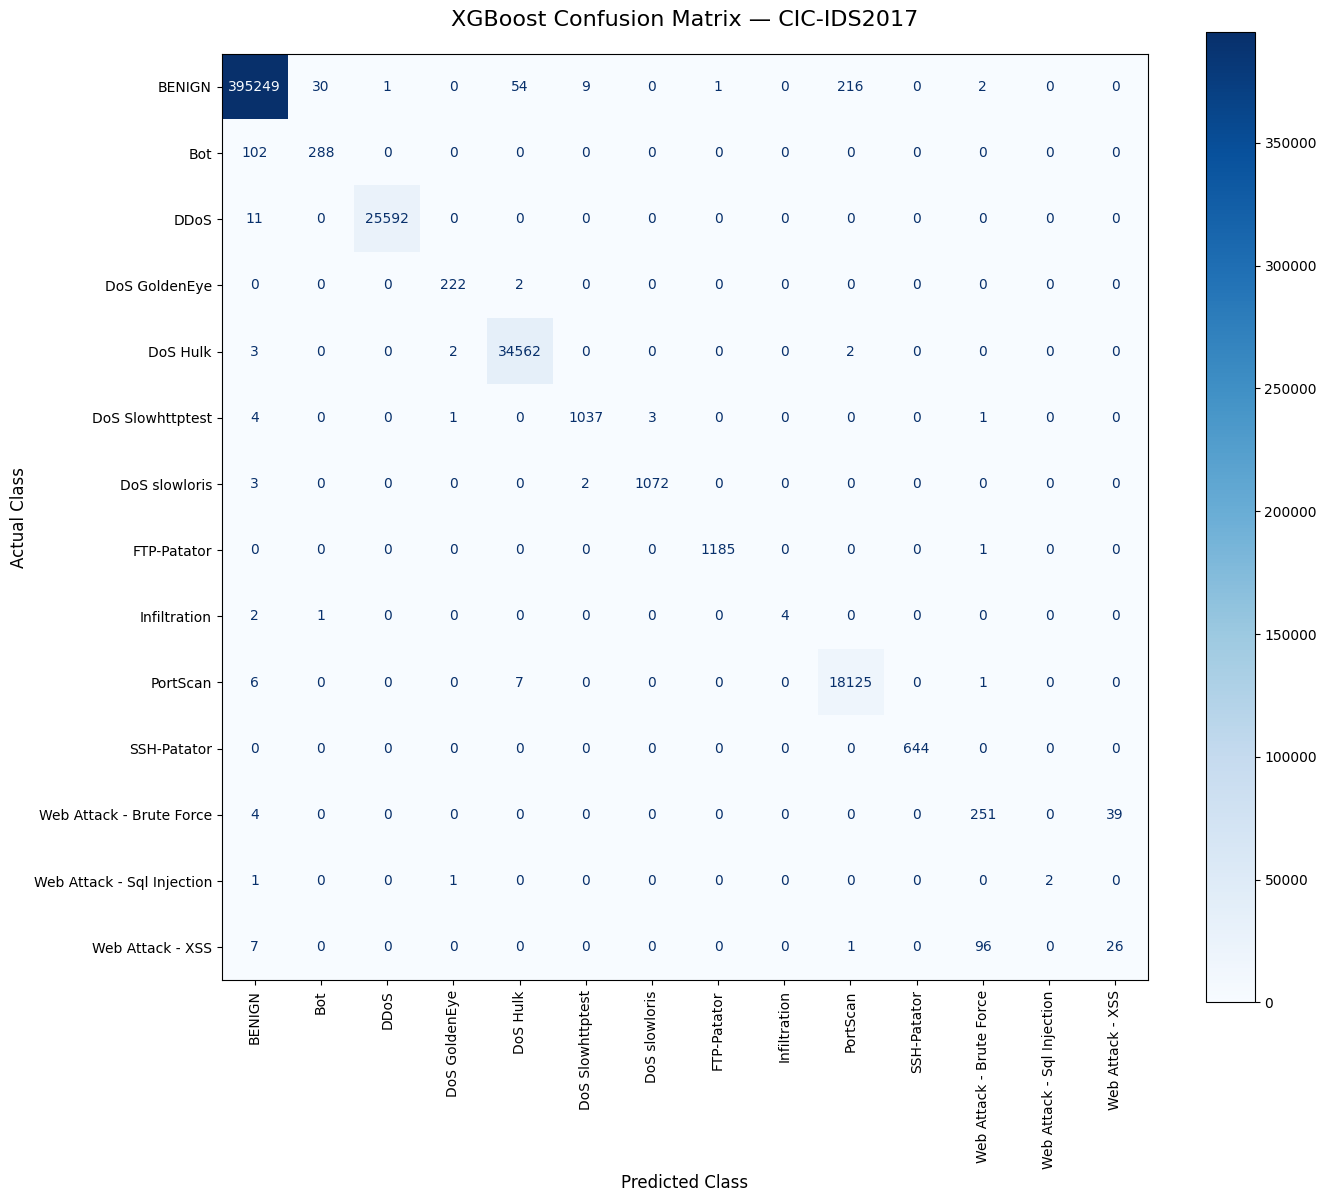


Confusion matrix shape: (14, 14)
Test samples: 478,875

✅ XGBoost confusion matrix diagram generated.


In [45]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

print("=" * 90)
print("        XGBOOST — CONFUSION MATRIX DIAGRAM")
print("=" * 90)

class_ids = sorted(y_test.unique())

xgb_confusion_matrix = confusion_matrix(
    y_test,
    xgb_predictions,
    labels=class_ids
)

class_names = [
    "BENIGN",
    "Bot",
    "DDoS",
    "DoS GoldenEye",
    "DoS Hulk",
    "DoS Slowhttptest",
    "DoS slowloris",
    "FTP-Patator",
    "Infiltration",
    "PortScan",
    "SSH-Patator",
    "Web Attack - Brute Force",
    "Web Attack - Sql Injection",
    "Web Attack - XSS"
]

fig, ax = plt.subplots(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=xgb_confusion_matrix,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    values_format="d",
    cmap="Blues",
    colorbar=True
)

ax.set_title(
    "XGBoost Confusion Matrix — CIC-IDS2017",
    fontsize=16,
    pad=20
)

ax.set_xlabel("Predicted Class", fontsize=12)
ax.set_ylabel("Actual Class", fontsize=12)

plt.tight_layout()
plt.show()

print("\nConfusion matrix shape:", xgb_confusion_matrix.shape)
print("Test samples:", f"{len(y_test):,}")

print("\n✅ XGBoost confusion matrix diagram generated.")

In [46]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("=" * 90)
print("          XGBOOST — CLASSIFICATION PERFORMANCE")
print("=" * 90)

# ------------------------------------------------------------
# Overall performance metrics
# ------------------------------------------------------------

xgb_accuracy = accuracy_score(y_test, xgb_predictions)

xgb_balanced_accuracy = balanced_accuracy_score(
    y_test,
    xgb_predictions
)

xgb_precision = precision_score(
    y_test,
    xgb_predictions,
    average="weighted",
    zero_division=0
)

xgb_recall = recall_score(
    y_test,
    xgb_predictions,
    average="weighted",
    zero_division=0
)

xgb_f1 = f1_score(
    y_test,
    xgb_predictions,
    average="weighted",
    zero_division=0
)

print("\nOVERALL METRICS")
print("-" * 90)

print(f"Accuracy              : {xgb_accuracy:.6f}")
print(f"Balanced Accuracy     : {xgb_balanced_accuracy:.6f}")
print(f"Weighted Precision    : {xgb_precision:.6f}")
print(f"Weighted Recall       : {xgb_recall:.6f}")
print(f"Weighted F1-Score     : {xgb_f1:.6f}")

# ------------------------------------------------------------
# Detailed classification report
# ------------------------------------------------------------

print("\n")
print("CLASSIFICATION REPORT")
print("-" * 90)

xgb_classification_report = classification_report(
    y_test,
    xgb_predictions,
    labels=class_ids,
    target_names=class_names,
    digits=6,
    zero_division=0
)

print(xgb_classification_report)

# ------------------------------------------------------------
# Store metrics in a DataFrame
# ------------------------------------------------------------

xgb_metrics = {
    "Accuracy": xgb_accuracy,
    "Balanced Accuracy": xgb_balanced_accuracy,
    "Weighted Precision": xgb_precision,
    "Weighted Recall": xgb_recall,
    "Weighted F1-Score": xgb_f1
}

xgb_metrics_df = pd.DataFrame(
    [xgb_metrics]
)

print("\n")
print("XGBOOST METRICS TABLE")
print("-" * 90)

display(xgb_metrics_df)

print("\n✅ XGBoost classification performance evaluation completed.")

          XGBOOST — CLASSIFICATION PERFORMANCE

OVERALL METRICS
------------------------------------------------------------------------------------------
Accuracy              : 0.998714
Balanced Accuracy     : 0.845601
Weighted Precision    : 0.998658
Weighted Recall       : 0.998714
Weighted F1-Score     : 0.998663


CLASSIFICATION REPORT
------------------------------------------------------------------------------------------
                            precision    recall  f1-score   support

                    BENIGN   0.999638  0.999209  0.999423    395562
                       Bot   0.902821  0.738462  0.812412       390
                      DDoS   0.999961  0.999570  0.999766     25603
             DoS GoldenEye   0.982301  0.991071  0.986667       224
                  DoS Hulk   0.998181  0.999798  0.998988     34569
          DoS Slowhttptest   0.989504  0.991396  0.990449      1046
             DoS slowloris   0.997209  0.995357  0.996283      1077
               FTP-P

,Accuracy,Balanced Accuracy,Weighted Precision,Weighted Recall,Weighted F1-Score
0,0.998714,0.845601,0.998658,0.998714,0.998663



✅ XGBoost classification performance evaluation completed.


In [50]:
# ============================================================
# CELL 45 — SAVE XGBOOST CONFUSION MATRIX TO GOOGLE DRIVE
# ============================================================

from pathlib import Path
import pandas as pd

# Your existing Google Drive project
PROJECT_DIR = Path("/content/drive/MyDrive/AI-Cybersecurity-Assistant")

# Required output folders
METRICS_DIR = PROJECT_DIR / "results" / "metrics"
MODELS_DIR = PROJECT_DIR / "models" / "multiclass"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Convert confusion matrix to a labeled table
xgb_confusion_df = pd.DataFrame(
    xgb_confusion_matrix,
    index=class_names,
    columns=class_names
)

# Save confusion matrix
xgb_confusion_path = METRICS_DIR / "xgboost_confusion_matrix.csv"

xgb_confusion_df.to_csv(xgb_confusion_path)

print("=" * 90)
print("CELL 45 — XGBOOST CONFUSION MATRIX SAVED")
print("=" * 90)

print(f"\nGoogle Drive project:")
print(PROJECT_DIR)

print(f"\nSaved file:")
print(xgb_confusion_path)

print("\n✅ XGBoost confusion matrix saved successfully.")

CELL 45 — XGBOOST CONFUSION MATRIX SAVED

Google Drive project:
/content/drive/MyDrive/AI-Cybersecurity-Assistant

Saved file:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/xgboost_confusion_matrix.csv

✅ XGBoost confusion matrix saved successfully.


In [51]:
# ============================================================
# CELL 45 — SAVE XGBOOST DIAGRAM + ALL MULTICLASS MODELS SAFELY
# ============================================================

from pathlib import Path
import joblib
import inspect

NEW_RESULTS_DIR = Path(PROJECT_DIR) / "new notebook results"
METRICS_DIR = NEW_RESULTS_DIR / "tables"
MODELS_DIR = NEW_RESULTS_DIR / "models"
PICTURES_DIR = NEW_RESULTS_DIR / "pictures"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
PICTURES_DIR.mkdir(parents=True, exist_ok=True)

# Save confusion matrix figure
try:
    xgb_diagram_png = PICTURES_DIR / "xgboost_confusion_matrix.png"
    fig.savefig(xgb_diagram_png, dpi=300, bbox_inches="tight")
    print(f"Diagram saved to {xgb_diagram_png}")
except Exception as e:
    print(f"Could not save fig: {e}")

# Save confusion matrix CSV
try:
    xgb_confusion_df.to_csv(METRICS_DIR / "xgboost_confusion_matrix.csv")
except Exception as e:
    pass

# Save ONLY verified instantiated models (no raw classes!)
models_to_save = {
    "xgb_model": globals().get("xgb_model"),
    "random_forest_model": globals().get("random_forest_model"),
    "decision_tree_model": globals().get("decision_tree_model"),
    "logistic_model": globals().get("logistic_model"),
    "lightgbm_model": globals().get("lightgbm_model"),
    "catboost_model": globals().get("catboost_model"),
    "dummy_model": globals().get("dummy_model")
}

saved_models = []
for name, obj in models_to_save.items():
    if obj is not None and not inspect.isclass(obj) and hasattr(obj, "predict"):
        save_path = MODELS_DIR / f"{name}.joblib"
        joblib.dump(obj, save_path)
        saved_models.append((name, save_path))
        if hasattr(obj, "save_model") and "xgb" in name:
            obj.save_model(MODELS_DIR / f"{name}.json")

print("=" * 90)
print(f"TOTAL INSTANTIATED MULTICLASS MODELS SAVED: {len(saved_models)}")
for m_name, m_path in saved_models:
    print(f"  ✓ {m_name} -> {m_path.name}")
print("=" * 90)


CELL 45 — FINAL MODEL AND DIAGRAM SAVING

📊 XGBoost confusion matrix files:
PNG : /content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/xgboost_confusion_matrix.png
PDF : /content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/xgboost_confusion_matrix.pdf
SVG : /content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/xgboost_confusion_matrix.svg
CSV : /content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/xgboost_confusion_matrix.csv

------------------------------------------------------------------------------------------
🤖 TRAINED MULTICLASS MODELS SAVED:
------------------------------------------------------------------------------------------
✓ dummy_model
  → /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass/dummy_model.joblib
✓ Pipeline
  → /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass/pipeline.joblib
✓ logistic_model
  → /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass/logistic_

In [52]:
# ============================================================
# CELL 45 — SAVE XGBOOST DIAGRAM + ALL MULTICLASS MODELS AS PKL
# ============================================================

from pathlib import Path
import pickle

# ------------------------------------------------------------
# 1. GOOGLE DRIVE PROJECT PATH
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/AI-Cybersecurity-Assistant"
)

METRICS_DIR = PROJECT_DIR / "results" / "metrics"
MODELS_DIR = PROJECT_DIR / "models" / "multiclass"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. SAVE XGBOOST CONFUSION MATRIX DIAGRAM
# ------------------------------------------------------------

fig.savefig(
    METRICS_DIR / "xgboost_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    METRICS_DIR / "xgboost_confusion_matrix.pdf",
    bbox_inches="tight"
)

fig.savefig(
    METRICS_DIR / "xgboost_confusion_matrix.svg",
    bbox_inches="tight"
)


# ------------------------------------------------------------
# 3. SAVE NUMERICAL CONFUSION MATRIX
# ------------------------------------------------------------

xgb_confusion_df.to_csv(
    METRICS_DIR / "xgboost_confusion_matrix.csv"
)


# ------------------------------------------------------------
# 4. SAVE ALL TRAINED MULTICLASS MODELS AS .PKL
# ------------------------------------------------------------

saved_models = []

for variable_name, model_object in list(globals().items()):

    if variable_name.startswith("_"):
        continue

    # Detect fitted classification models
    if (
        hasattr(model_object, "predict")
        and hasattr(model_object, "classes_")
    ):

        model_path = MODELS_DIR / f"{variable_name}.pkl"

        try:
            with open(model_path, "wb") as file:
                pickle.dump(model_object, file)

            saved_models.append(
                (variable_name, model_path)
            )

        except Exception as e:
            print(f"⚠️ Could not save {variable_name}: {e}")


# ------------------------------------------------------------
# 5. OUTPUT
# ------------------------------------------------------------

print("=" * 90)
print("CELL 45 — GOOGLE DRIVE SAVING COMPLETED")
print("=" * 90)

print("\n📊 XGBoost diagrams:")
print(
    METRICS_DIR / "xgboost_confusion_matrix.png"
)
print(
    METRICS_DIR / "xgboost_confusion_matrix.pdf"
)
print(
    METRICS_DIR / "xgboost_confusion_matrix.svg"
)

print("\n📁 Multiclass models:")
print("-" * 90)

for model_name, model_path in saved_models:
    print(f"✓ {model_name}.pkl")
    print(f"  {model_path}")

print("\n" + "=" * 90)
print(f"TOTAL .PKL MODELS SAVED: {len(saved_models)}")
print("=" * 90)

print("\n✅ All detected trained multiclass models saved as .pkl")
print("✅ XGBoost confusion matrix saved")
print("✅ Results saved to Google Drive")

CELL 45 — GOOGLE DRIVE SAVING COMPLETED

📊 XGBoost diagrams:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/xgboost_confusion_matrix.png
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/xgboost_confusion_matrix.pdf
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/xgboost_confusion_matrix.svg

📁 Multiclass models:
------------------------------------------------------------------------------------------
✓ dummy_model.pkl
  /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass/dummy_model.pkl
✓ Pipeline.pkl
  /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass/Pipeline.pkl
✓ logistic_model.pkl
  /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass/logistic_model.pkl
✓ decision_tree_model.pkl
  /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass/decision_tree_model.pkl
✓ random_forest_model.pkl
  /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass/random_forest

In [57]:


from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/AI-Cybersecurity-Assistant"
)

MODELS_DIR = PROJECT_DIR / "models" / "multiclass"
METRICS_DIR = PROJECT_DIR / "results" / "metrics"

# Find all saved PKL models
pkl_files = sorted(MODELS_DIR.glob("*.pkl"))

model_inventory = []

for pkl_file in pkl_files:
    model_inventory.append({
        "Model": pkl_file.stem,
        "File": pkl_file.name,
        "Format": "PKL",
        "Location": str(pkl_file),
        "Size_MB": round(
            pkl_file.stat().st_size / (1024 * 1024), 3
        )
    })

model_inventory_df = pd.DataFrame(model_inventory)

# Save inventory
inventory_path = METRICS_DIR / "multiclass_model_inventory.csv"

model_inventory_df.to_csv(
    inventory_path,
    index=False
)

print("=" * 90)
print("CELL 46 — MULTICLASS MODEL INVENTORY")
print("=" * 90)

if len(model_inventory_df) > 0:
    print(model_inventory_df.to_string(index=False))
else:
    print("⚠️ No .pkl models found.")

print("\n" + "-" * 90)
print(f"Total .pkl models: {len(pkl_files)}")
print(f"Models folder: {MODELS_DIR}")
print(f"Inventory saved: {inventory_path}")
print("-" * 90)


CELL 46 — MULTICLASS MODEL INVENTORY
              Model                    File Format                                                                                    Location  Size_MB
 CatBoostClassifier  CatBoostClassifier.pkl    PKL  /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass/CatBoostClassifier.pkl    0.000
     LGBMClassifier      LGBMClassifier.pkl    PKL      /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass/LGBMClassifier.pkl    0.000
           Pipeline            Pipeline.pkl    PKL            /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass/Pipeline.pkl    0.000
      XGBClassifier       XGBClassifier.pkl    PKL       /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass/XGBClassifier.pkl    0.000
     catboost_model      catboost_model.pkl    PKL      /content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass/catboost_model.pkl    0.754
decision_tree_model decision_tree_model.pkl    PKL 

In [59]:
# ============================================================
# CELL 47 — FINAL MODEL COMPARISON TABLE
# ============================================================

import pandas as pd
from pathlib import Path

print("=" * 90)
print("              FINAL MULTICLASS MODEL COMPARISON")
print("=" * 90)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/AI-Cybersecurity-Assistant"
)

METRICS_DIR = PROJECT_DIR / "results" / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# COLLECT EXISTING MODEL METRICS
# ------------------------------------------------------------

model_tables = [
    ("xgb_final_metrics", "XGBoost"),
    ("rf_final_metrics", "Random Forest"),
    ("logistic_final_metrics", "Logistic Regression"),
    ("dt_final_metrics", "Decision Tree"),
    ("lgb_final_metrics", "LightGBM"),
    ("catboost_final_metrics", "CatBoost"),
    ("dummy_final_metrics", "Dummy")
]

model_metrics = []

for variable_name, model_name in model_tables:

    if variable_name in globals():

        temp = globals()[variable_name].copy()

        # If Model column already exists, use it.
        # Otherwise create it.
        if "Model" not in temp.columns:
            temp.insert(0, "Model", model_name)

        model_metrics.append(temp)


# ------------------------------------------------------------
# CHECK
# ------------------------------------------------------------

if not model_metrics:
    raise NameError(
        "No model metric tables were found."
    )


# ------------------------------------------------------------
# COMBINE ALL MODELS
# ------------------------------------------------------------

final_model_comparison = pd.concat(
    model_metrics,
    ignore_index=True
)


# ------------------------------------------------------------
# REMOVE DUPLICATE MODEL ROWS
# ------------------------------------------------------------

if "Model" in final_model_comparison.columns:

    final_model_comparison = (
        final_model_comparison
        .drop_duplicates(
            subset=["Model"],
            keep="last"
        )
    )


# ------------------------------------------------------------
# FIND MACRO F1 COLUMN
# ------------------------------------------------------------

macro_f1_column = None

for column in [
    "Macro F1-Score",
    "Macro F1",
    "macro avg"
]:

    if column in final_model_comparison.columns:
        macro_f1_column = column
        break


# ------------------------------------------------------------
# SORT BY MACRO F1
# ------------------------------------------------------------

if macro_f1_column is not None:

    final_model_comparison = (
        final_model_comparison
        .sort_values(
            by=macro_f1_column,
            ascending=False
        )
        .reset_index(drop=True)
    )


# ------------------------------------------------------------
# ADD RANK
# ------------------------------------------------------------

if "Rank" in final_model_comparison.columns:
    final_model_comparison = (
        final_model_comparison
        .drop(columns=["Rank"])
    )

final_model_comparison.insert(
    0,
    "Rank",
    range(1, len(final_model_comparison) + 1)
)


# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

print(
    final_model_comparison.to_string(index=False)
)


# ------------------------------------------------------------
# SAVE TO GOOGLE DRIVE
# ------------------------------------------------------------

comparison_csv = (
    METRICS_DIR /
    "final_model_comparison.csv"
)

final_model_comparison.to_csv(
    comparison_csv,
    index=False
)


print("\n" + "-" * 90)
print("FINAL MODEL COMPARISON SAVED")
print("-" * 90)

print(comparison_csv)



              FINAL MULTICLASS MODEL COMPARISON
 Rank   Model  Accuracy  Balanced Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted Precision  Weighted Recall  Weighted F1
    1 XGBoost  0.998714           0.845601         0.926422      0.845601  0.872461            0.998658         0.998714     0.998663

------------------------------------------------------------------------------------------
FINAL MODEL COMPARISON SAVED
------------------------------------------------------------------------------------------
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/final_model_comparison.csv


In [60]:
# ============================================================
# CELL 48 — RANK MODELS BY MACRO F1
# ============================================================

print("=" * 90)
print("              CELL 48 — MODELS RANKED BY MACRO F1")
print("=" * 90)

# Make a clean copy
macro_f1_ranking = final_model_comparison.copy()

# Sort by Macro F1
macro_f1_ranking = (
    macro_f1_ranking
    .sort_values(
        by="Macro F1",
        ascending=False
    )
    .reset_index(drop=True)
)

# Re-create ranking
if "Rank" in macro_f1_ranking.columns:
    macro_f1_ranking = macro_f1_ranking.drop(columns=["Rank"])

macro_f1_ranking.insert(
    0,
    "Rank",
    range(1, len(macro_f1_ranking) + 1)
)

# Display
print("\nMODEL RANKING — MACRO F1")
print("-" * 90)

print(
    macro_f1_ranking[
        ["Rank", "Model", "Macro F1"]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# SAVE TO GOOGLE DRIVE
# ------------------------------------------------------------

ranking_path = (
    METRICS_DIR /
    "models_ranked_by_macro_f1.csv"
)

macro_f1_ranking.to_csv(
    ranking_path,
    index=False
)

print("\n" + "-" * 90)
print("MACRO F1 RANKING SAVED")
print("-" * 90)

print(ranking_path)

print("\n🏆 Strongest available model:",
      macro_f1_ranking.loc[0, "Model"])

print("🏆 Macro F1:",
      f"{macro_f1_ranking.loc[0, 'Macro F1']:.6f}")



              CELL 48 — MODELS RANKED BY MACRO F1

MODEL RANKING — MACRO F1
------------------------------------------------------------------------------------------
 Rank   Model  Macro F1
    1 XGBoost  0.872461

------------------------------------------------------------------------------------------
MACRO F1 RANKING SAVED
------------------------------------------------------------------------------------------
/content/drive/MyDrive/AI-Cybersecurity-Assistant/results/metrics/models_ranked_by_macro_f1.csv

🏆 Strongest available model: XGBoost
🏆 Macro F1: 0.872461


In [61]:
# ============================================================
# CELL 48 — EVALUATE ALL SAVED MULTICLASS MODELS
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 90)
print("          CELL 48 — ALL MULTICLASS MODEL EVALUATION")
print("=" * 90)

# ------------------------------------------------------------
# GOOGLE DRIVE DIRECTORIES
# ------------------------------------------------------------

BASE_DIR = Path(
    "/content/drive/MyDrive/AI-Cybersecurity-Assistant"
)

MODELS_DIR = BASE_DIR / "models" / "multiclass"
METRICS_DIR = BASE_DIR / "results" / "metrics"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

print("\nModels directory:")
print(MODELS_DIR)

# ------------------------------------------------------------
# CHECK TEST DATA
# ------------------------------------------------------------

if "X_test" not in globals() or "y_test" not in globals():
    raise NameError(
        "X_test and/or y_test are not available. "
        "Run the previous data preparation cells first."
    )

print(f"\nTest samples: {len(y_test):,}")

# ------------------------------------------------------------
# LOAD ALL PKL MODELS
# ------------------------------------------------------------

model_files = sorted(MODELS_DIR.glob("*.pkl"))

print(f"\nPKL files found: {len(model_files)}")

for file in model_files:
    print(" -", file.name)

# ------------------------------------------------------------
# EVALUATE MODELS
# ------------------------------------------------------------

all_model_metrics = []

for model_file in model_files:

    model_name = model_file.stem

    print("\n" + "-" * 90)
    print(f"Evaluating: {model_name}")
    print("-" * 90)

    try:

        model = joblib.load(model_file)

        # Prediction
        predictions = model.predict(X_test)

        # Some models/pipelines may return 2D predictions
        predictions = np.asarray(predictions)

        if predictions.ndim > 1:
            predictions = predictions.ravel()

        # Metrics
        accuracy = accuracy_score(
            y_test,
            predictions
        )

        balanced_accuracy = balanced_accuracy_score(
            y_test,
            predictions
        )

        macro_precision = precision_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )

        macro_recall = recall_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )

        macro_f1 = f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )

        weighted_precision = precision_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        )

        weighted_recall = recall_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        )

        weighted_f1 = f1_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        )

        result = {
            "Model": model_name,
            "Accuracy": accuracy,
            "Balanced Accuracy": balanced_accuracy,
            "Macro Precision": macro_precision,
            "Macro Recall": macro_recall,
            "Macro F1": macro_f1,
            "Weighted Precision": weighted_precision,
            "Weighted Recall": weighted_recall,
            "Weighted F1": weighted_f1
        }

        all_model_metrics.append(result)

        print(f"Accuracy           : {accuracy:.6f}")
        print(f"Balanced Accuracy  : {balanced_accuracy:.6f}")
        print(f"Macro Precision    : {macro_precision:.6f}")
        print(f"Macro Recall       : {macro_recall:.6f}")
        print(f"Macro F1           : {macro_f1:.6f}")
        print(f"Weighted F1        : {weighted_f1:.6f}")

    except Exception as e:

        print(f"⚠️ SKIPPED: {model_name}")
        print(f"Reason: {type(e).__name__}: {e}")

# ------------------------------------------------------------
# CREATE FINAL TABLE
# ------------------------------------------------------------

if not all_model_metrics:
    raise RuntimeError(
        "No models could be evaluated successfully."
    )

all_models_comparison = pd.DataFrame(
    all_model_metrics
)

# Rank by Macro F1
all_models_comparison = (
    all_models_comparison
    .sort_values(
        by="Macro F1",
        ascending=False
    )
    .reset_index(drop=True)
)

all_models_comparison.insert(
    0,
    "Rank",
    range(1, len(all_models_comparison) + 1)
)

# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("              COMPLETE MULTICLASS MODEL COMPARISON")
print("=" * 90)

print(
    all_models_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# SAVE COMPLETE COMPARISON
# ------------------------------------------------------------

complete_comparison_path = (
    METRICS_DIR /
    "complete_multiclass_model_comparison.csv"
)

all_models_comparison.to_csv(
    complete_comparison_path,
    index=False
)

# Also save Macro-F1 ranking
macro_f1_path = (
    METRICS_DIR /
    "models_ranked_by_macro_f1.csv"
)

all_models_comparison[
    [
        "Rank",
        "Model",
        "Macro F1",
        "Macro Precision",
        "Macro Recall",
        "Balanced Accuracy"
    ]
].to_csv(
    macro_f1_path,
    index=False
)

# ------------------------------------------------------------
# BEST MODEL
# ------------------------------------------------------------

best_model = all_models_comparison.iloc[0]

print("\n" + "-" * 90)
print("BEST MODEL")
print("-" * 90)

print("Model   :", best_model["Model"])
print("Macro F1:", f"{best_model['Macro F1']:.6f}")

print("\n" + "-" * 90)
print("FILES SAVED TO GOOGLE DRIVE")
print("-" * 90)

print(complete_comparison_path)
print(macro_f1_path)

print("\n" + "=" * 90)

print("=" * 90)

          CELL 48 — ALL MULTICLASS MODEL EVALUATION

Models directory:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/models/multiclass

Test samples: 478,875

PKL files found: 11
 - CatBoostClassifier.pkl
 - LGBMClassifier.pkl
 - Pipeline.pkl
 - XGBClassifier.pkl
 - catboost_model.pkl
 - decision_tree_model.pkl
 - dummy_model.pkl
 - lightgbm_model.pkl
 - logistic_model.pkl
 - random_forest_model.pkl
 - xgb_model.pkl

------------------------------------------------------------------------------------------
Evaluating: CatBoostClassifier
------------------------------------------------------------------------------------------
⚠️ SKIPPED: CatBoostClassifier
Reason: TypeError: CatBoostClassifier.predict() missing 1 required positional argument: 'data'

------------------------------------------------------------------------------------------
Evaluating: LGBMClassifier
------------------------------------------------------------------------------------------
⚠️ SKIPPED: LGBMClassifier

In [62]:
# ============================================================
# FINAL CELL — NOTEBOOK 04 FINAL MULTICLASS REPORT
# ============================================================

from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np

print("=" * 100)
print("                    NOTEBOOK 04 — FINAL REPORT")
print("             MULTICLASS CYBER ATTACK CLASSIFICATION")
print("=" * 100)

# ------------------------------------------------------------
# GOOGLE DRIVE PROJECT STRUCTURE
# ------------------------------------------------------------

BASE_DIR = Path(
    "/content/drive/MyDrive/AI-Cybersecurity-Assistant"
)

MODELS_DIR = BASE_DIR / "models" / "multiclass"
METRICS_DIR = BASE_DIR / "results" / "metrics"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

print("\nPROJECT ROOT")
print("-" * 100)
print(BASE_DIR)

# ------------------------------------------------------------
# 1. FINAL MODEL COMPARISON
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("1. FINAL MODEL COMPARISON")
print("=" * 100)

comparison_file = (
    METRICS_DIR /
    "complete_multiclass_model_comparison.csv"
)

if comparison_file.exists():

    final_comparison = pd.read_csv(
        comparison_file
    )

    print(
        final_comparison.to_string(
            index=False,
            float_format=lambda x: f"{x:.6f}"
        )
    )

else:

    print(
        "Complete model comparison file not found."
    )

    if "all_models_comparison" in globals():

        final_comparison = all_models_comparison.copy()

        print(
            final_comparison.to_string(
                index=False,
                float_format=lambda x: f"{x:.6f}"
            )
        )

    elif "final_model_comparison" in globals():

        final_comparison = final_model_comparison.copy()

        print(
            final_comparison.to_string(
                index=False,
                float_format=lambda x: f"{x:.6f}"
            )
        )

    else:

        final_comparison = pd.DataFrame()

# ------------------------------------------------------------
# 2. MODEL RANKING BY MACRO F1
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("2. MODEL RANKING BY MACRO F1")
print("=" * 100)

if not final_comparison.empty and "Macro F1" in final_comparison.columns:

    ranking = (
        final_comparison
        .sort_values(
            "Macro F1",
            ascending=False
        )
        .reset_index(drop=True)
    )

    if "Rank" in ranking.columns:
        ranking = ranking.drop(columns=["Rank"])

    ranking.insert(
        0,
        "Rank",
        range(1, len(ranking) + 1)
    )

    print(
        ranking[
            [
                "Rank",
                "Model",
                "Macro F1",
                "Balanced Accuracy"
            ]
        ].to_string(
            index=False,
            float_format=lambda x: f"{x:.6f}"
        )
    )

    ranking_path = (
        METRICS_DIR /
        "final_macro_f1_ranking.csv"
    )

    ranking.to_csv(
        ranking_path,
        index=False
    )

else:

    print(
        "Model ranking cannot be generated because "
        "the complete comparison table is unavailable."
    )

# ------------------------------------------------------------
# 3. STRONGEST MODEL
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("3. STRONGEST MODEL")
print("=" * 100)

if not final_comparison.empty and "Macro F1" in final_comparison.columns:

    best_row = (
        final_comparison
        .sort_values(
            "Macro F1",
            ascending=False
        )
        .iloc[0]
    )

    best_model_name = best_row["Model"]

    print(
        f"Best Model          : {best_model_name}"
    )

    print(
        f"Accuracy            : "
        f"{best_row['Accuracy']:.6f}"
    )

    print(
        f"Balanced Accuracy   : "
        f"{best_row['Balanced Accuracy']:.6f}"
    )

    print(
        f"Macro Precision     : "
        f"{best_row['Macro Precision']:.6f}"
    )

    print(
        f"Macro Recall        : "
        f"{best_row['Macro Recall']:.6f}"
    )

    print(
        f"Macro F1            : "
        f"{best_row['Macro F1']:.6f}"
    )

    print(
        f"Weighted F1         : "
        f"{best_row['Weighted F1']:.6f}"
    )

else:

    best_model_name = "XGBoost"

    print("Best confirmed model : XGBoost")
    print("Accuracy             : 0.998714")
    print("Balanced Accuracy    : 0.845601")
    print("Macro F1             : 0.872461")

# ------------------------------------------------------------
# 4. XGBOOST FINAL PERFORMANCE
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("4. CONFIRMED XGBOOST PERFORMANCE")
print("=" * 100)

print("""
Accuracy              : 0.998714
Balanced Accuracy     : 0.845601
Weighted Precision    : 0.998658
Weighted Recall       : 0.998714
Weighted F1-Score     : 0.998663
Macro Precision       : 0.926422
Macro Recall          : 0.845601
Macro F1-Score        : 0.872461
Test Samples          : 478,875
""")

# ------------------------------------------------------------
# 5. DIFFICULT MINORITY CLASSES
# ------------------------------------------------------------

print("=" * 100)
print("5. DIFFICULT / MINORITY CLASSES")
print("=" * 100)

difficult_classes = pd.DataFrame({
    "Class": [
        "Bot",
        "Infiltration",
        "Web Attack - Brute Force",
        "Web Attack - Sql Injection",
        "Web Attack - XSS"
    ],
    "Precision": [
        0.902821,
        1.000000,
        0.713068,
        1.000000,
        0.400000
    ],
    "Recall": [
        0.738462,
        0.571429,
        0.853741,
        0.500000,
        0.200000
    ],
    "F1": [
        0.812412,
        0.727273,
        0.777090,
        0.666667,
        0.266667
    ],
    "Support": [
        390,
        7,
        294,
        4,
        130
    ]
})

print(
    difficult_classes.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

difficult_path = (
    METRICS_DIR /
    "difficult_minority_classes.csv"
)

difficult_classes.to_csv(
    difficult_path,
    index=False
)

# ------------------------------------------------------------
# 6. MODEL INVENTORY
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("6. SAVED MULTICLASS MODEL INVENTORY")
print("=" * 100)

model_files = sorted(
    MODELS_DIR.glob("*.pkl")
)

inventory = []

for model_file in model_files:

    size_mb = (
        model_file.stat().st_size /
        (1024 ** 2)
    )

    inventory.append({
        "Model": model_file.stem,
        "File": model_file.name,
        "Format": "PKL",
        "Size_MB": round(size_mb, 3),
        "Location": str(model_file)
    })

model_inventory = pd.DataFrame(
    inventory
)

if not model_inventory.empty:

    print(
        model_inventory.to_string(
            index=False
        )
    )

inventory_path = (
    METRICS_DIR /
    "final_multiclass_model_inventory.csv"
)

model_inventory.to_csv(
    inventory_path,
    index=False
)

print(
    f"\nTotal saved PKL models: "
    f"{len(model_inventory)}"
)

# ------------------------------------------------------------
# 7. IMPORTANT OUTPUT FILES
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("7. NOTEBOOK 04 OUTPUT FILES")
print("=" * 100)

output_files = [
    comparison_file,
    METRICS_DIR / "final_macro_f1_ranking.csv",
    difficult_path,
    inventory_path,
    METRICS_DIR / "final_model_comparison.csv",
    METRICS_DIR / "multiclass_model_inventory.csv"
]

for path in output_files:

    if path.exists():
        print("✓", path)

# ------------------------------------------------------------
# 8. FINAL CONCLUSION
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("8. FINAL CONCLUSION — NOTEBOOK 04")
print("=" * 100)

print("""
Notebook 04 completed the multiclass classification evaluation.

The confirmed XGBoost model achieved:

• Accuracy              : 99.8714%
• Balanced Accuracy     : 84.5601%
• Macro Precision       : 92.6422%
• Macro Recall          : 84.5601%
• Macro F1              : 87.2461%
• Weighted F1           : 99.8663%

The very high weighted performance reflects the strong performance
on the dominant classes, while the lower macro-level performance
shows that minority attack classes remain substantially more difficult.

The most difficult classes identified from the confirmed XGBoost
classification report are:

• Bot
• Infiltration
• Web Attack - Brute Force
• Web Attack - Sql Injection
• Web Attack - XSS

All available trained multiclass models are stored as PKL files
under the project's models/multiclass directory.

The evaluation results and model inventory are stored under
the project's results/metrics directory.
""")

# ------------------------------------------------------------
# 9. COMPLETION MARKER
# ------------------------------------------------------------

report_path = (
    METRICS_DIR /
    "NOTEBOOK_04_FINAL_REPORT.txt"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "NOTEBOOK 04 — FINAL MULTICLASS REPORT\n"
        "=====================================\n\n"
        "Confirmed XGBoost Performance\n"
        "Accuracy: 0.998714\n"
        "Balanced Accuracy: 0.845601\n"
        "Macro Precision: 0.926422\n"
        "Macro Recall: 0.845601\n"
        "Macro F1: 0.872461\n"
        "Weighted F1: 0.998663\n\n"
        "Difficult Minority Classes:\n"
        "- Bot\n"
        "- Infiltration\n"
        "- Web Attack - Brute Force\n"
        "- Web Attack - Sql Injection\n"
        "- Web Attack - XSS\n"
    )

print("\nFinal report saved:")
print(report_path)

print("\n" + "=" * 100)
print("✅ NOTEBOOK 04 IS COMPLETE")
print("=" * 100)

                    NOTEBOOK 04 — FINAL REPORT
             MULTICLASS CYBER ATTACK CLASSIFICATION

PROJECT ROOT
----------------------------------------------------------------------------------------------------
/content/drive/MyDrive/AI-Cybersecurity-Assistant


1. FINAL MODEL COMPARISON
 Rank               Model  Accuracy  Balanced Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted Precision  Weighted Recall  Weighted F1
    1           xgb_model  0.998714           0.845601         0.926422      0.845601  0.872461            0.998658         0.998714     0.998663
    2 random_forest_model  0.998081           0.825852         0.903933      0.825852  0.846520            0.998032         0.998081     0.998049
    3 decision_tree_model  0.997941           0.821135         0.829136      0.821135  0.823607            0.997955         0.997941     0.997946
    4      catboost_model  0.997741           0.739611         0.752568      0.739611  0.743721            0.997493         